In [1]:
import collections, json, math, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import confusion_matrix

DATA_DIR = Path('data')
TEST_FRAC = 0.2   # what % of data is tested on at the end
SEED = 0

In [2]:
def read_jsonl(raw):
    dec = json.JSONDecoder()
    for line in raw.decode('utf-8').splitlines():
        line, pos = line.strip(), 0
        if not line or line.startswith('#'):
            continue
        while pos < len(line):
            obj, pos = dec.raw_decode(line, pos)
            yield obj
            while pos < len(line) and line[pos].isspace():
                pos += 1

#flags data as either plain or background
def load_trials():
    # skip anything named test (data/test.jsonl, data/test/...): those are long recordings, not training trials
    files = sorted(f for f in DATA_DIR.rglob('*.jsonl') if 'test' not in f.relative_to(DATA_DIR).with_suffix('').parts)
    trials = []
    for f in files:
        base = re.sub(r'_AD$', '', re.sub(r'_\d+$', '', f.stem))
        flag = 'background' if base.endswith('_background') else 'plain'
        site = base[:-len('_background')] if flag == 'background' else base
        recs = sorted((r for r in read_jsonl(f.read_bytes()) if r.get('trace')), key=lambda r: r['ts'])
        n_test = math.ceil(len(recs) * TEST_FRAC)
        for i, r in enumerate(recs):
            trace = np.asarray(r['trace'], dtype=np.float64)
            dur = (r.get('durationMs') or 10000) / 1000
            times = (np.asarray(r['times'], dtype=np.float64) / 1000 if r.get('times') is not None
                     else (np.arange(len(trace)) + 0.5) * dur / len(trace))
            trials.append(dict(trace=trace, times=times, site=site, flag=flag,
                               test=i >= len(recs) - n_test))
    return trials

trials = load_trials()
SITES = sorted({t['site'] for t in trials}, key=lambda s: (s != 'idle', s))
site = np.array([t['site'] for t in trials], dtype=object)
flag = np.array([t['flag'] for t in trials], dtype=object)
test = np.array([t['test'] for t in trials])
train = ~test

print(f'{len(trials)} trials | train {train.sum()}, test {test.sum()}\n')
print(f'  {"site":<12}{"plain":>7}{"background":>12}')
for s in SITES:
    print(f'  {s:<12}{((site == s) & (flag == "plain")).sum():>7}{((site == s) & (flag == "background")).sum():>12}')

1602 trials | train 1281, test 321

  site          plain  background
  idle            100         100
  chatgpt         100         100
  coupang         102         100
  figma           100         100
  google          100         100
  instagram       100         100
  navermap        100         100
  youtube         100         100


In [12]:
# ---- Training chunks from the long recordings ----
# Long recordings made with server.py's "Long recording with visit log" hold the real visits
# (rec['visits']: t = ms since recording start, url, by) and tab events (rec['events']). This cuts them
# into 10 s chunks shaped like a training trial and adds them to the training data:
#   * a chunk from 2 s before each logged visit to 8 s after it, labelled with that site
#   * idle chunks from quiet stretches (no visit inside, at least AFTER_VISIT_S after the last one).
#     These include tab closes and cache resets, so the models also see real "not a visit" examples.
# The newest LONG_TEST_LAST logged recordings are held out: the long-trace check in the last cell
# scores only those, since a recording the models trained on would score too well.
from urllib.parse import urlparse

LONG_FILE = DATA_DIR / 'test.jsonl'
LONG_TEST_LAST = 2         # newest logged recordings kept out of training, for the long-trace check
LONG_FLAG = 'plain'        # nothing ran in the background during the long recordings
NEW_TAB_IS_GOOGLE = True   # Chrome's new-tab page is Google's search page: opening one is a google visit
CHUNK_S, CHUNK_OPEN_S = 10.0, 2.0   # same shape as a training trial: 10 s, the site opens 2 s in
AFTER_VISIT_S = 8.0        # an idle chunk starts at least this long after a visit (a site stays open 8 s)
IDLE_STEP_S = 5.0          # quiet stretches give an idle chunk every this many seconds

def site_of_url(url):
    """Model site name for a visited URL (as logged by server.py), or the host if it is not one of them."""
    host = urlparse(url).hostname or url
    if 'naver' in host:
        return 'navermap'
    return next((s for s in SITES if s != 'idle' and s in host), host)

def is_new_tab(e):
    return e['kind'] == 'tab_open' and ('newtab' in e['url'] or 'new-tab-page' in e['url'])

def logged_visits(rec):
    """Real visits in a long recording, sorted: (time s, site, by). New tabs count as google visits."""
    out = [(v['t'] / 1000, site_of_url(v['url']), v.get('by', 'user')) for v in rec.get('visits') or []]
    if NEW_TAB_IS_GOOGLE:
        out += [(e['t'] / 1000, 'google', 'newtab') for e in rec.get('events') or [] if is_new_tab(e)]
    return sorted(out)

def cut_chunk(trace, times, t0):
    lo, hi = np.searchsorted(times, [t0, t0 + CHUNK_S])
    return dict(trace=trace[lo:hi].copy(), times=times[lo:hi] - t0)

logged_recs = ([r for r in read_jsonl(LONG_FILE.read_bytes())
                if r.get('trace') and r.get('times') is not None and 'visits' in r]
               if LONG_FILE.exists() else [])
long_train = logged_recs[:max(len(logged_recs) - LONG_TEST_LAST, 0)]
LONG_TRAINED = {r['startedAt'] for r in long_train}   # the last cell marks these recordings

chunks, skipped = [], []
for r in long_train:
    trace = np.asarray(r['trace'], dtype=np.float64)
    times = np.asarray(r['times'], dtype=np.float64) / 1000
    end, visits = times[-1], logged_visits(r)
    for t, s, by in visits:
        if s not in SITES:
            skipped.append(f'{s} at {t:.1f} s (not one of the trained sites)')
        elif t - CHUNK_OPEN_S < 0 or t - CHUNK_OPEN_S + CHUNK_S > end:
            skipped.append(f'{s} at {t:.1f} s (too close to the start/end of the recording)')
        else:
            chunks.append(dict(cut_chunk(trace, times, t - CHUNK_OPEN_S), site=s, flag=LONG_FLAG,
                               test=False, source='long'))
    vt = np.array([t for t, _, _ in visits])
    for t0 in np.arange(0, end - CHUNK_S, IDLE_STEP_S):
        if not ((vt > t0 - AFTER_VISIT_S) & (vt < t0 + CHUNK_S)).any():
            chunks.append(dict(cut_chunk(trace, times, t0), site='idle', flag=LONG_FLAG,
                               test=False, source='long'))

trials = [t for t in trials if t.get('source') != 'long'] + chunks   # safe to re-run
site = np.array([t['site'] for t in trials], dtype=object)
flag = np.array([t['flag'] for t in trials], dtype=object)
test = np.array([t['test'] for t in trials])
train = ~test

print(f'{len(logged_recs)} logged long recording(s): {len(long_train)} used for training, '
      f'{len(logged_recs) - len(long_train)} held out for the long-trace check')
counts = collections.Counter(t['site'] for t in chunks)
print(f'{len(chunks)} chunks added to training: ' + ', '.join(f'{s} {counts[s]}' for s in SITES if counts[s]))
for msg in skipped:
    print(f'  skipped {msg}')

4 logged long recording(s): 2 used for training, 2 held out for the long-trace check
60 chunks added to training: idle 6, chatgpt 7, coupang 8, figma 8, google 8, instagram 8, navermap 8, youtube 7


In [13]:
# ---- Timing slack (training only) ----
# The models lean on the first 0.1-0.5 s after a site opens, so a site that opens a little early or late
# gets misnamed. That happens in long traces, where the scan's windows are 0.1 s apart and a page load
# never starts exactly on cue. So every TRAINING trial also goes in as copies whose whole trace is moved
# by each of SHIFTS_S seconds: the site then opens at 2 + shift s. Test trials are never shifted, so the
# test numbers still measure trials as recorded.
# A copy shares its trace with the original and only stores its shift (the traces already take ~1 GB);
# features() applies the shift through apply_shift().
SHIFTS_S = (-0.2, -0.1, 0.1, 0.2)   # () turns it off

def apply_shift(t):
    """(trace, times) of trial t moved t['shift'] seconds later (no 'shift' key: unchanged).
    The gap that opens at one edge is filled with the original reads at those same times:
    quiet pre-open reads at the start, the slowly-changing tail at the end."""
    trace, times, d = t['trace'], t['times'], t.get('shift', 0.0)
    if d > 0:     # later: reads before d s are repeated to fill the start
        head = times < d
        return np.concatenate([trace[head], trace]), np.concatenate([times[head], times + d])
    if d < 0:     # earlier: the first -d s drop off, the last -d s are repeated to fill the end
        end = times[-1]
        keep, tail = times >= -d, times > end + d
        return np.concatenate([trace[keep], trace[tail]]), np.concatenate([times[keep] + d, times[tail]])
    return trace, times

trials = [t for t in trials if not t.get('shift')]   # safe to re-run: drop copies from an earlier run
trials = trials + [dict(t, shift=d) for t in trials if not t['test'] for d in SHIFTS_S]
site = np.array([t['site'] for t in trials], dtype=object)
flag = np.array([t['flag'] for t in trials], dtype=object)
test = np.array([t['test'] for t in trials])
train = ~test
n_copies = sum(bool(t.get('shift')) for t in trials)
print(f'timing slack {SHIFTS_S} s: {len(trials)} trials | train {train.sum()} ({n_copies} shifted copies), test {test.sum()}')

timing slack (-0.2, -0.1, 0.1, 0.2) s: 7026 trials | train 6705 (5364 shifted copies), test 321


In [14]:
USE_S = 10.0                  # seconds from the start of the recording (the site opens at 2 s)
BIN_S = 0.1                   # bin width
SPIKE_MS = 0.5                # latencies are clipped to this before averaging
SPIKE_THRESHOLDS = (SPIKE_MS, 2.0)
BASELINE = (0.5, 2.0)         # pre-open window used for normalisation

def features(t):
    trace, times = apply_shift(t)   # timing slack: shifted training copies
    #splits data into exactly 100 bins of 0.1s
    n_bins = int(round(USE_S / BIN_S))
    keep = times < USE_S
    idx = np.minimum((times[keep] / BIN_S).astype(int), n_bins - 1) 

    lat = np.clip(trace[keep], 0, SPIKE_MS) #clips spikes to 0.5ms max
    base = slice(int(BASELINE[0] / BIN_S), int(BASELINE[1] / BIN_S)) #used to calculate baseline latency
    count = np.bincount(idx, minlength=n_bins).astype(float) #count the amount of reads in each bin

    n = np.maximum(count, 1) #prevents division by 0
    mean = np.bincount(idx, lat, n_bins) / n #mean latency in each bin
    rel_mean = mean / mean[base].mean()                          # mean latency, x baseline
    rel_count = count / max(count[base].mean(), 1e-9)            # reads per bin, x baseline
    spikes = [np.bincount(idx, trace[keep] > thr, n_bins) / n for thr in SPIKE_THRESHOLDS] #spikes over 0.5ms and 2ms
    sd = np.sqrt(np.maximum(np.bincount(idx, lat ** 2, n_bins) / n - mean ** 2, 0))
    rel_sd = sd / max(mean[base].mean(), 1e-9)                   # spread, x baseline mean
    return np.concatenate([rel_mean, rel_count, *spikes, rel_sd])

X = np.stack([features(t) for t in trials])
assert np.isfinite(X).all()
print(f'{X.shape[1]} features per trial')

500 features per trial


In [15]:
def extra_trees():
    return ExtraTreesClassifier(n_estimators=1000, max_features=0.5, random_state=SEED, n_jobs=-1)

def boosting():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          l2_regularization=1.0, early_stopping=False, random_state=SEED)

def voting_model():
    return VotingClassifier([('hgb', boosting()), ('et', extra_trees())], voting='soft')

class Hierarchical:
    """Router picks plain vs background; that kind's expert names the site."""
    def __init__(self):
        self.router = voting_model()
        self.experts = {'plain': voting_model(), 'background': voting_model()}

    def fit(self, X, site, flag):
        self.router.fit(X, flag)
        for k, m in self.experts.items():
            m.fit(X[flag == k], site[flag == k])
        return self

    def predict(self, X):
        route = self.router.predict(X)
        out = np.empty(len(X), dtype=object)
        for k, m in self.experts.items():
            if (route == k).any():
                out[route == k] = m.predict(X[route == k])
        return out, route

In [16]:
flat = voting_model().fit(X[train], site[train])
hier = Hierarchical().fit(X[train], site[train], flag[train])
print('trained')

trained


Accuracy, 8 sites (random guess 0.125)

                 train    test
flat             1.000   0.919
hierarchical     1.000   0.913
  router                 0.997   (plain vs background)

Test accuracy by kind of trial
  plain       flat 0.932   hierarchical 0.925   (161 trials)
  background  flat 0.906   hierarchical 0.900   (160 trials)


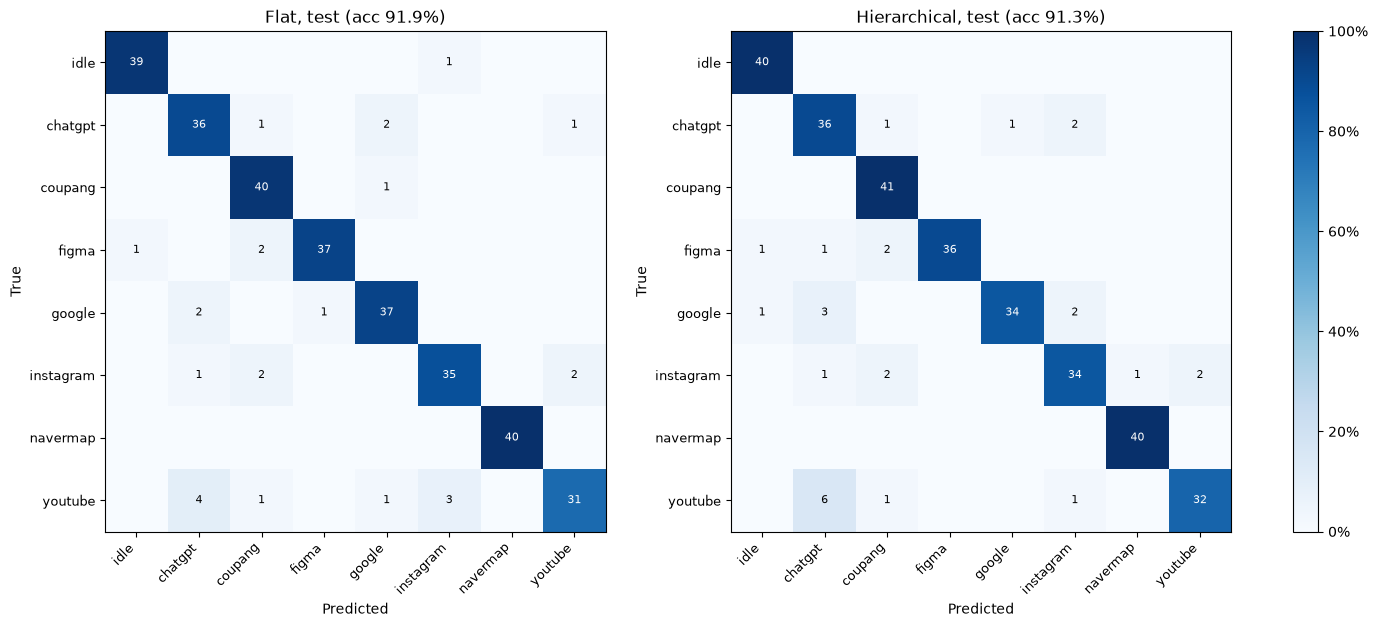

In [17]:
def plot_cm(ax, true, pred, names, title):
    cm = confusion_matrix(true, pred, labels=names)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                        color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(names)), names, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(names)), names, fontsize=9)
    ax.set(xlabel='Predicted', ylabel='True', title=title)
    ax.grid(False)
    return im

acc = lambda p, t: np.mean(p == t)
st, ft = site[test], flag[test]
pred_flat = flat.predict(X[test])
pred_hier, route = hier.predict(X[test])
train_flat = flat.predict(X[train])
train_hier, _ = hier.predict(X[train])

print(f'Accuracy, {len(SITES)} sites (random guess {1 / len(SITES):.3f})\n')
print(f'{"":<14}{"train":>8}{"test":>8}')
print(f'{"flat":<14}{acc(train_flat, site[train]):>8.3f}{acc(pred_flat, st):>8.3f}')
print(f'{"hierarchical":<14}{acc(train_hier, site[train]):>8.3f}{acc(pred_hier, st):>8.3f}')
print(f'{"  router":<14}{"":>8}{acc(route, ft):>8.3f}   (plain vs background)')

print('\nTest accuracy by kind of trial')
for f in ('plain', 'background'):
    sel = ft == f
    print(f'  {f:<11} flat {acc(pred_flat[sel], st[sel]):.3f}   hierarchical {acc(pred_hier[sel], st[sel]):.3f}   ({sel.sum()} trials)')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_cm(axes[0], st, pred_flat, SITES, f'Flat, test (acc {acc(pred_flat, st):.1%})')
im = plot_cm(axes[1], st, pred_hier, SITES, f'Hierarchical, test (acc {acc(pred_hier, st):.1%})')
fig.colorbar(im, ax=axes, fraction=0.025, format=PercentFormatter(1))
plt.show()

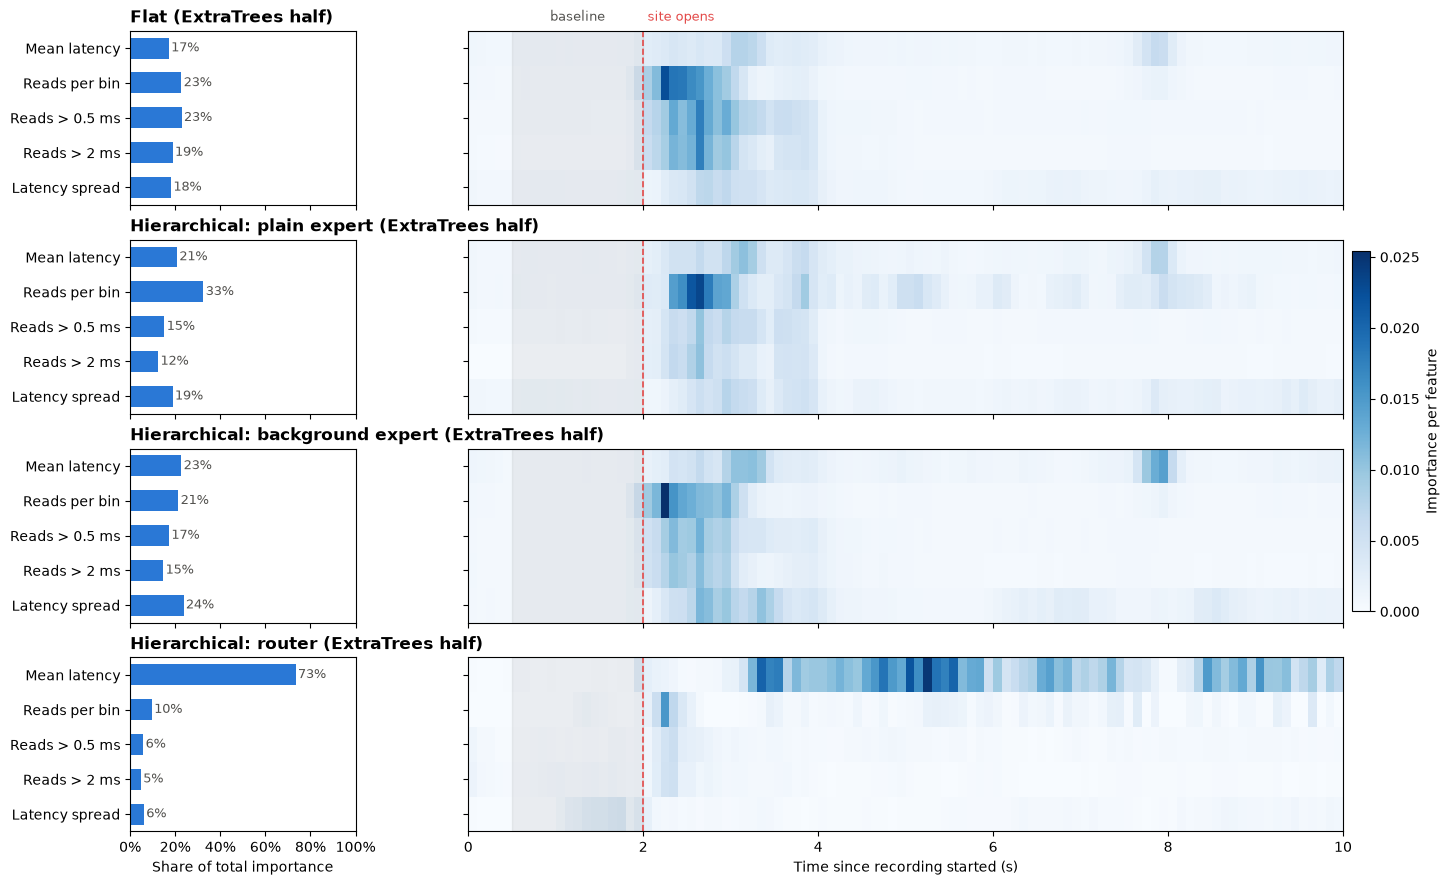

In [18]:
# Feature importance (impurity importance, measured on the training data).
# Boosting has no comparable importance, so each voting model's ExtraTrees half stands in for it.
BLOCKS = ['Mean latency', 'Reads per bin', f'Reads > {SPIKE_THRESHOLDS[0]:g} ms',
          f'Reads > {SPIKE_THRESHOLDS[1]:g} ms', 'Latency spread']
n_bins = int(round(USE_S / BIN_S))
models = {'Flat': flat,
          'Hierarchical: plain expert': hier.experts['plain'],
          'Hierarchical: background expert': hier.experts['background'],
          'Hierarchical: router': hier.router}
imp = {f'{name} (ExtraTrees half)': m.named_estimators_['et'].feature_importances_.reshape(len(BLOCKS), n_bins)
       for name, m in models.items()}
vmax = max(v.max() for v in imp.values())

fig, axes = plt.subplots(len(models), 2, figsize=(16, 2.6 * len(models)),
                         gridspec_kw=dict(width_ratios=[1, 4]), sharex='col', sharey=True)
for (name, I), (ax_bar, ax_map) in zip(imp.items(), axes):
    # left: share of the model's importance in each measurement
    share = I.sum(1)
    ax_bar.barh(range(len(BLOCKS)), share, color='#2a78d6', height=0.6)
    for i, v in enumerate(share):
        ax_bar.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9, color='#52514e')
    ax_bar.set_xlim(0, 1)
    ax_bar.set_title(name, loc='left', fontweight='bold')
    ax_bar.xaxis.set_major_formatter(PercentFormatter(1))
    ax_bar.invert_yaxis()
    # right: where in time that importance sits
    im = ax_map.imshow(I, aspect='auto', cmap='Blues', vmin=0, vmax=vmax, interpolation='nearest',
                       extent=(0, USE_S, len(BLOCKS) - 0.5, -0.5))
    ax_map.axvline(2, color='#e34948', lw=1.2, ls='--')
    ax_map.axvspan(*BASELINE, color='#52514e', alpha=0.08)
    ax_map.grid(False)
axes[0, 1].text(2.05, -0.7, 'site opens', color='#e34948', fontsize=9, va='bottom')
axes[0, 1].text(sum(BASELINE) / 2, -0.7, 'baseline', color='#52514e', fontsize=9, va='bottom', ha='center')
for ax in axes[:, 0]:
    ax.set_yticks(range(len(BLOCKS)), BLOCKS)
axes[-1, 0].set_xlabel('Share of total importance')
axes[-1, 1].set_xlabel('Time since recording started (s)')
fig.colorbar(im, ax=axes[:, 1], fraction=0.02, pad=0.01, label='Importance per feature')
plt.show()

In [19]:
# ---- Find site visits in a long trace ----
# The models only know 10 s windows where a site opens at 2 s. So slide a 10 s window along the
# long trace and ask the model about every position:
#   1. visit score = 1 - P(idle). It is high when a site opens about 2 s into the window.
#   2. Take the highest-scoring window, call it a visit, and name the site from that same window.
#      The score peaks within ~0.1 s of the real visit, which matters: the models lean on the
#      first 0.1-0.5 s after the site opens.
#   3. Skip windows within MIN_GAP_S of that visit and repeat until no score is above THRESHOLD.
# The trace needs ~2 s of quiet before each visit (the baseline), and visits closer than MIN_GAP_S merge.

STEP_S = 0.1      # how far the window slides each step
MIN_GAP_S = 8.0   # two visits must be at least this far apart
THRESHOLD = 0.5   # minimum visit score to count as a visit
OPEN_S = 2.0      # where the site opens inside a training window

def window(trace, times, t0):
    """The USE_S seconds of the long trace starting at t0, re-timed so the window starts at 0."""
    lo, hi = np.searchsorted(times, [t0, t0 + USE_S])
    return dict(trace=trace[lo:hi], times=times[lo:hi] - t0)

def site_proba(model, X):
    """P(site) for each row, columns in SITES order. Works for the flat and the hierarchical model."""
    if hasattr(model, 'experts'):
        route = model.router.predict(X)
        parts = [(route == k, m) for k, m in model.experts.items()]
    else:
        parts = [(np.ones(len(X), bool), model)]
    P = np.zeros((len(X), len(SITES)))
    for sel, m in parts:
        if sel.any():
            P[np.ix_(sel, [SITES.index(c) for c in m.classes_])] = m.predict_proba(X[sel])
    return P

def find_visits(trace, times, model):
    """Returns (visits, starts, P). Each visit is a dict: time (s), site, confidence, score."""
    starts = np.arange(0, times[-1] - USE_S + STEP_S + 1e-9, STEP_S)   # last window may miss < STEP_S at the end
    if len(starts) == 0:
        raise ValueError(f'trace must be longer than {USE_S:g} s')
    Xw = np.stack([features(window(trace, times, t0)) for t0 in starts])
    Xw = np.nan_to_num(Xw, nan=0.0, posinf=0.0, neginf=0.0)   # windows with no reads in the baseline
    P = site_proba(model, Xw)
    score = 1 - P[:, SITES.index('idle')]
    Q = P.copy(); Q[:, SITES.index('idle')] = 0                # site probabilities without idle
    taken, visits = np.zeros(len(starts), bool), []
    for i in np.argsort(-score, kind='stable'):
        if score[i] < THRESHOLD:
            break
        if taken[i]:
            continue
        taken |= np.abs(starts - starts[i]) < MIN_GAP_S
        visits.append(dict(time=starts[i] + OPEN_S, site=SITES[Q[i].argmax()],
                           confidence=Q[i].max(), score=score[i]))
    return sorted(visits, key=lambda v: v['time']), starts, P

def load_long_traces(path):
    """Every recording in a recorder .jsonl file -> list of (record, trace ms, times s)."""
    out = []
    for r in read_jsonl(Path(path).read_bytes()):
        if not r.get('trace'):
            continue
        if r.get('times') is None:
            raise ValueError('recording has no per-read times; record it with the current recorder')
        out.append((r, np.asarray(r['trace'], dtype=np.float64), np.asarray(r['times'], dtype=np.float64) / 1000))
    return out

5 recording(s) in data/test.jsonl

Recording 1 (2026-11-24T14:54:19.126Z, 784 s): 48 visit(s) detected, 48 logged  [USED FOR TRAINING: not a fair test]
  real (s)  by     real site  found (s)  found site  conf
      11.4  server youtube         11.2  youtube      89%
      24.8  server google          24.8  google       78%
      41.0  server instagram       40.9  instagram    77%
      54.5  server navermap        54.5  navermap     88%
      67.0  server figma           67.1  figma        95%
      86.2  server coupang         86.3  coupang      93%
     104.2  server chatgpt        104.2  chatgpt      84%
     116.5  server youtube        116.6  youtube      97%
     133.9  server chatgpt        133.9  chatgpt      94%
     150.8  server google         150.6  google       88%
     166.8  server navermap       166.7  navermap     89%
     184.4  server instagram      184.2  instagram    69%
     198.5  server figma          198.6  figma        88%
     214.3  server coupang        21

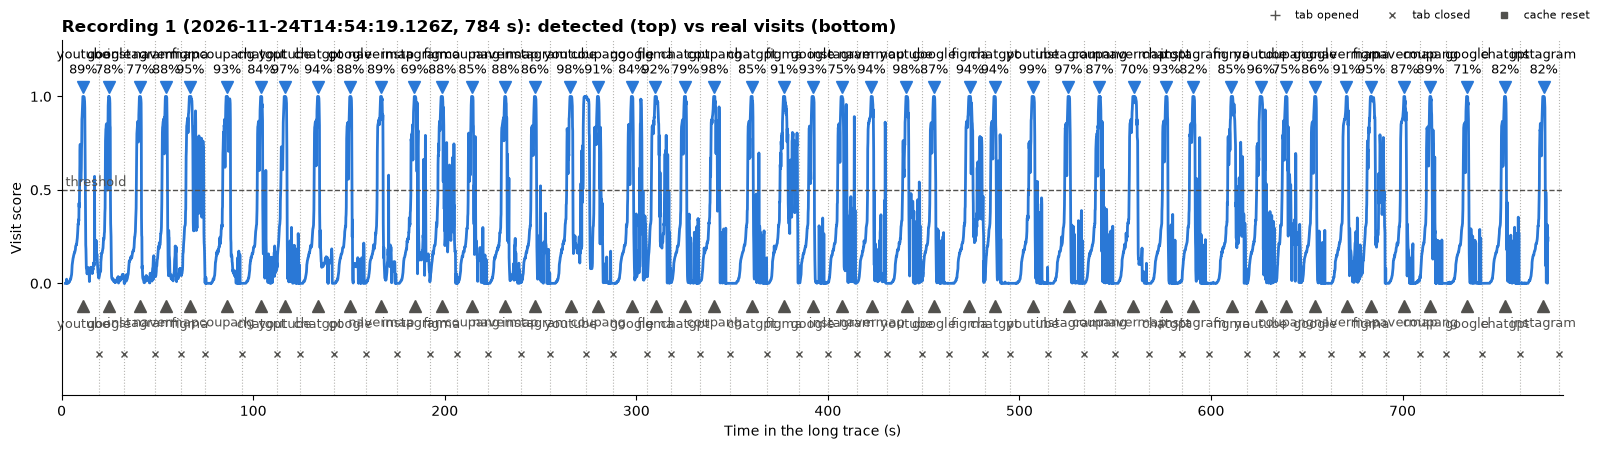


Recording 2 (2026-11-24T15:07:38.140Z, 100 s): 6 visit(s) detected, 6 logged  [USED FOR TRAINING: not a fair test]
  real (s)  by     real site  found (s)  found site  conf
       4.1  server navermap         4.1  navermap     89%
      21.8  server youtube         21.7  youtube      96%
      36.1  server figma           36.1  figma        95%
      54.7  server google          54.5  google       85%
      73.5  server coupang         73.6  coupang      82%
      86.4  server instagram       86.4  instagram    89%
  found 6/6 visits, 6 with the right site, 0 false alarm(s)


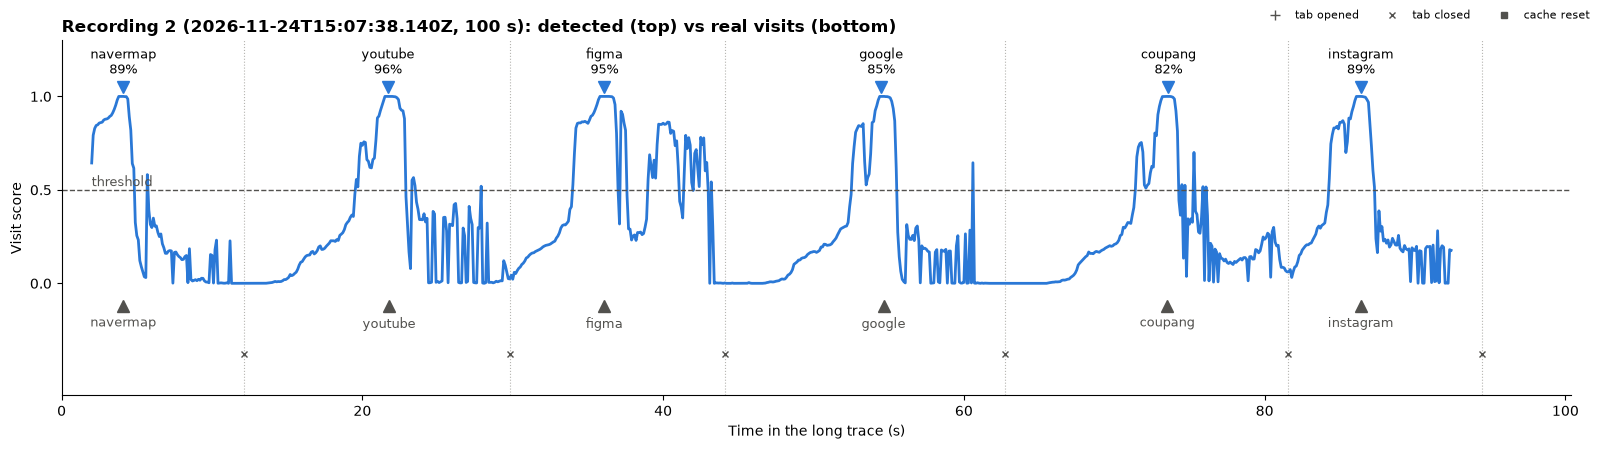


Recording 3 (2026-11-24T15:09:23.171Z, 66 s): 4 visit(s) detected, 4 logged  [held out]
  real (s)  by     real site  found (s)  found site  conf
      11.5  server instagram       11.6  instagram    69%
      28.1  server coupang         27.9  coupang      78%
      42.8  server navermap        42.8  navermap     82%
      56.2  server google          56.2  google       69%
  found 4/4 visits, 4 with the right site, 0 false alarm(s)


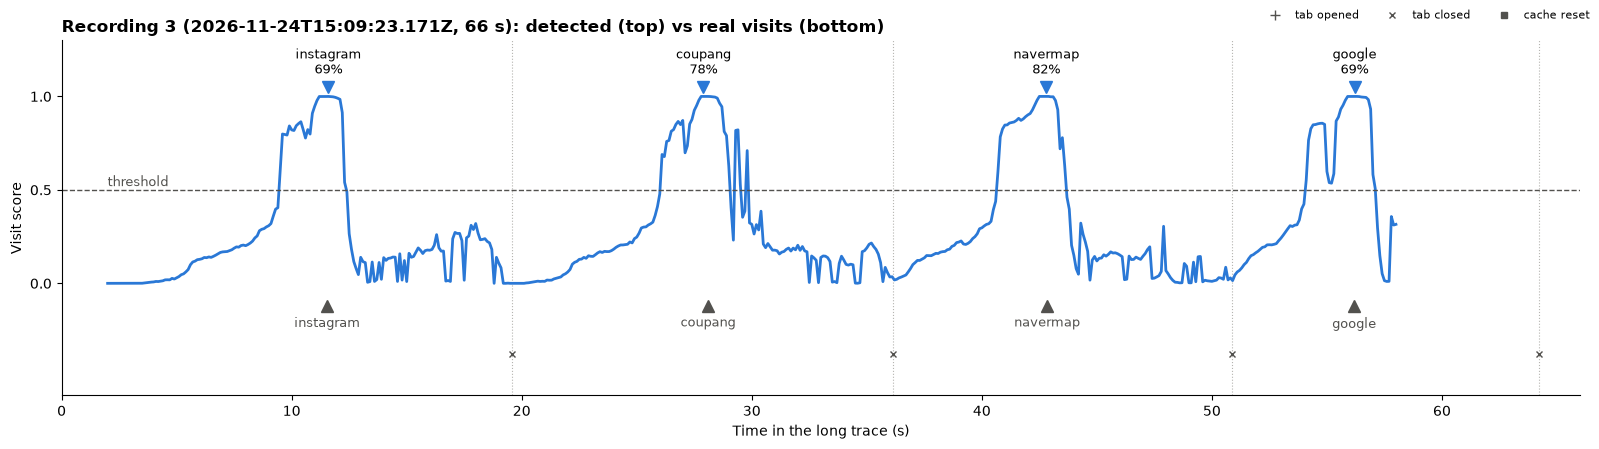


Recording 4 (2026-11-24T15:14:20.995Z, 570 s): 36 visit(s) detected, 36 logged  [held out]
  real (s)  by     real site  found (s)  found site  conf
       5.4  server navermap         5.4  navermap     70%
      19.2  server coupang         19.0  coupang      74%
      34.2  server figma           34.4  figma        82%
      46.3  server google          46.1  google       68%
      66.2  server youtube         65.8  youtube      81%
      81.2  server chatgpt         81.3  instagram    38%  <- wrong site
     100.4  server instagram      100.2  instagram    72%
     114.9  server youtube        114.8  youtube      81%
     130.2  server google         130.3  google       72%
     145.3  server instagram      145.3  google       77%  <- wrong site
     158.3  server figma          158.3  figma        90%
     174.0  server chatgpt        174.1  chatgpt      65%
     191.7  server coupang        191.6  coupang      77%
     206.3  server navermap       206.1  navermap     87%
     223

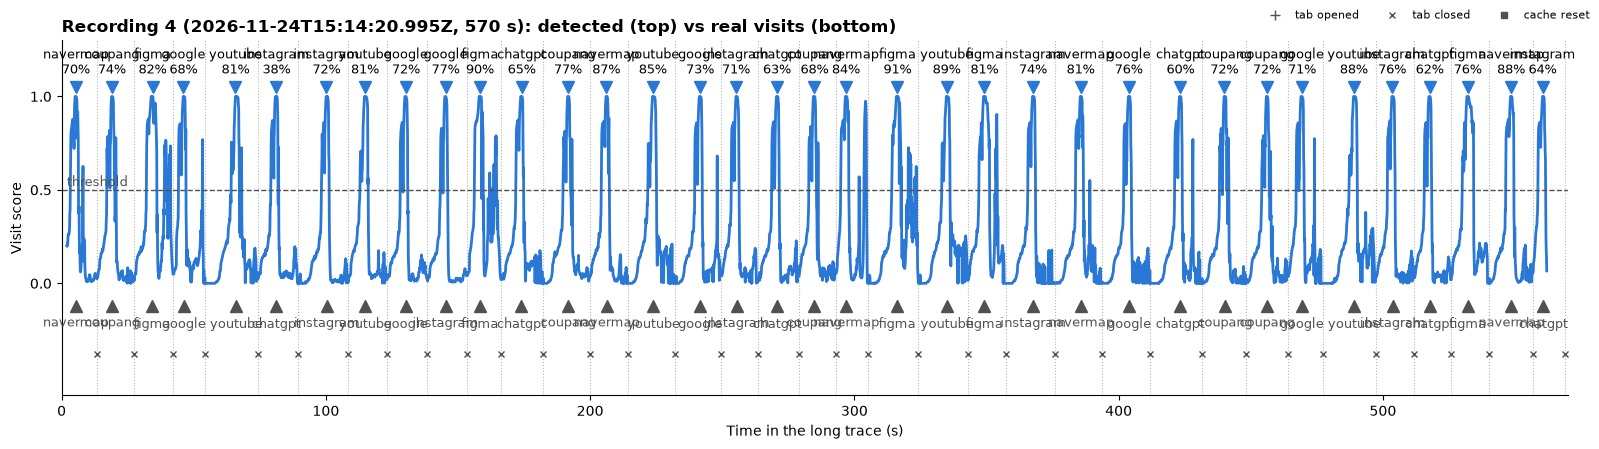


Recording 5 (2026-11-24T15:29:36.181Z, 216 s): 11 visit(s) detected, 9 logged  [held out]
  real (s)  by     real site  found (s)  found site  conf
      15.9  user   instagram       16.0  google       54%  <- wrong site
      46.1  newtab google          46.4  google       70%
      58.5  user   youtube       missed
      78.4  newtab google          78.6  google       74%
      92.6  user   coupang         92.5  coupang      51%
     123.3  newtab google         123.4  google       70%
     141.7  user   figma          141.8  figma        78%
     167.0  newtab google         167.3  google       72%
     181.2  user   chatgpt        181.2  google       66%  <- wrong site
    (none)                          2.0  google       29%  <- false alarm
    (none)                         37.7  google       35%  <- false alarm (near tab closed at 38.8 s)
    (none)                        153.5  google       50%  <- false alarm
  found 8/9 visits, 6 with the right site, 3 false alarm(s)


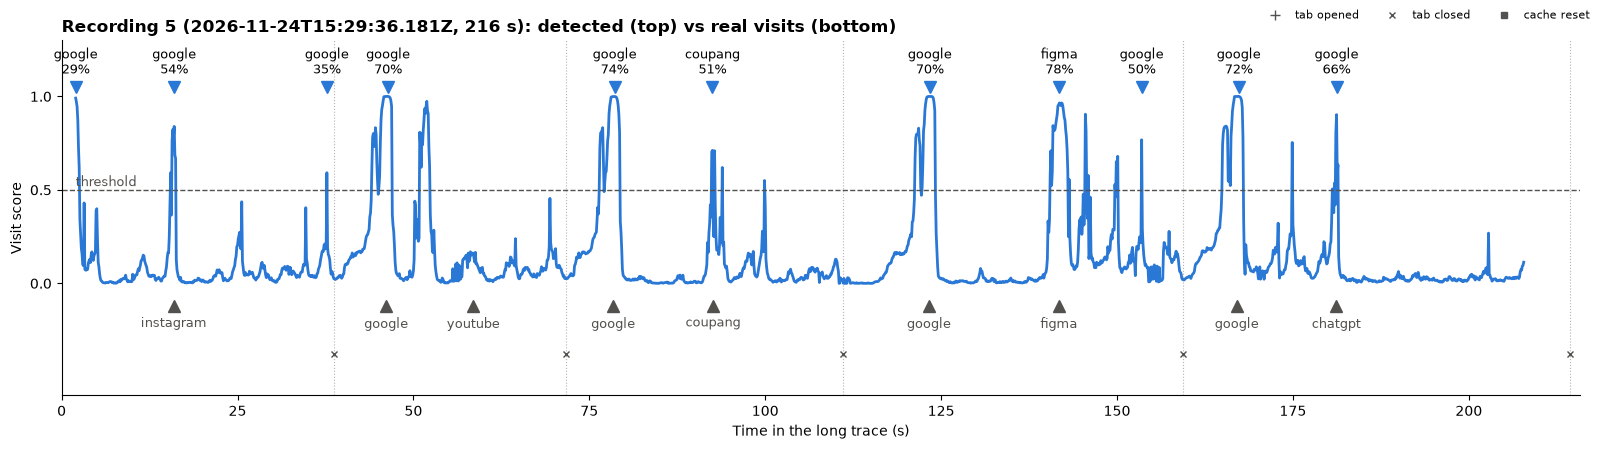


Held-out recordings: found 48/49 visits, 43 with the right site, 3 false alarm(s)


In [21]:
# Find the visits in every recording in LONG_FILE (data/test.jsonl).
# Recordings made with server.py's "Long recording with visit log" also hold
#   rec['visits']: the real visits (t = ms since recording start, url, by = 'server' | 'user')
#   rec['events']: tab opened / closed and OS page-cache resets (t, kind, url), to explain
#                  detections that are not visits
# so the detections are checked against them (site_of_url, logged_visits: the long-chunks cell).
# Recordings that were cut into training chunks are marked: their scores are not a fair test, so the
# total at the end counts only the held-out ones.

def event_label(e):
    if e['kind'] == 'tab_close':
        return 'tab closed'
    if e['kind'] == 'cache_reset':
        return 'cache reset'
    if e['kind'] == 'cache_reset_failed':
        return 'cache reset FAILED'
    url = e['url']
    if url.startswith(('http://', 'https://')):
        return f'tab opened: {site_of_url(url)}'
    if is_new_tab(e):
        return 'new tab'
    return f"tab opened: {url or '?'}"

def plot_visits(visits, starts, P, title='Detected visits', truth=(), events=()):
    """truth: optional (time s, site) of the real visits, drawn under the plot.
    events: optional (time s, label) of other logged events, drawn as dotted lines with markers in a
    strip below the real visits: + tab opened (labelled), x tab closed, square cache reset."""
    score = 1 - P[:, SITES.index('idle')]
    fig, ax = plt.subplots(figsize=(16, 4.5 if len(events) else 4))
    markers = {'tab closed': 'x', 'cache reset': 's', 'cache reset FAILED': 's'}
    for t, label in events:
        ax.axvline(t, ymin=0, ymax=1, color='#b5b4b0', lw=0.8, ls=':', zorder=0)
        y = -0.52 if label.startswith('cache reset') else -0.38   # resets follow closes within ms: own row
        ax.plot(t, y, markers.get(label, '+'), color='#52514e', ms=5 if label in markers else 7,
                mfc='none' if label == 'cache reset FAILED' else '#52514e')
        if label not in markers:
            ax.text(t, -0.44, label, ha='center', va='top', fontsize=8, color='#52514e')
    if len(events):
        kinds = [('+', 'tab opened', 7), ('x', 'tab closed', 5), ('s', 'cache reset', 5)]
        fig.legend([plt.Line2D([], [], ls='', marker=m, color='#52514e', ms=ms) for m, _, ms in kinds],
                   [k for _, k, _ in kinds], loc='upper right', ncol=3, fontsize=8, frameon=False)
    ax.plot(starts + OPEN_S, score, color='#2a78d6', lw=2)
    ax.axhline(THRESHOLD, color='#52514e', lw=1, ls='--')
    ax.text(starts[0] + OPEN_S, THRESHOLD + 0.02, 'threshold', color='#52514e', fontsize=9)
    for v in visits:
        ax.plot(v['time'], 1.05, 'v', color='#2a78d6', ms=8)
        ax.text(v['time'], 1.1, f"{v['site']}\n{v['confidence']:.0%}", ha='center', va='bottom', fontsize=9)
    for t, s in truth:
        ax.plot(t, -0.12, '^', color='#52514e', ms=8)
        ax.text(t, -0.18, s, ha='center', va='top', fontsize=9, color='#52514e')
    bottom = -0.6 if len(events) else -0.32 if len(truth) else -0.05
    ax.set(ylim=(bottom, 1.3), xlim=(0, starts[-1] + USE_S), yticks=[0, 0.5, 1],
           xlabel='Time in the long trace (s)', ylabel='Visit score')
    ax.set_title(title, loc='left', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()

MODEL = hier      # or flat
MATCH_S = 1.0     # a detection within this many seconds of a real visit counts as finding it
EXPLAIN_S = 2.0   # a false alarm this close to a tab event is shown next to it

recordings = load_long_traces(LONG_FILE)
print(f'{len(recordings)} recording(s) in {LONG_FILE}')
total = collections.Counter()   # over held-out recordings only
for n, (rec, trace, times) in enumerate(recordings, 1):
    visits, starts, P = find_visits(trace, times, MODEL)
    trained_on = rec.get('startedAt') in LONG_TRAINED
    name = f"Recording {n} ({rec.get('startedAt', 'no start time')}, {times[-1]:.0f} s)"

    if 'visits' not in rec:   # no visit log: just list the detections
        print(f'\n{name}: {len(visits)} visit(s) detected')
        for v in visits:
            print(f"  {v['time']:>7.1f} s  {v['site']:<11}{v['confidence']:>5.0%}")
        plot_visits(visits, starts, P, title=f'{name}: detected visits with confidence')
        continue

    truth = logged_visits(rec)
    print(f'\n{name}: {len(visits)} visit(s) detected, {len(truth)} logged'
          + ('  [USED FOR TRAINING: not a fair test]' if trained_on else '  [held out]'))
    # other browser events; a tab opening onto a logged visit is that visit, so it is left out
    events = [(e['t'] / 1000, event_label(e)) for e in rec.get('events', [])
              if not (e['kind'] == 'tab_open' and any(abs(e['t'] / 1000 - t) < 0.5 for t, _, _ in truth))]
    failed = sum(e['kind'] == 'cache_reset_failed' for e in rec.get('events', []))
    if failed:
        print(f'  WARNING: {failed} cache reset(s) failed during this recording (see the server log)')
    # a visit is only visible to the scan with OPEN_S of trace before it and USE_S - OPEN_S after it
    lo, hi = starts[0] + OPEN_S - 0.05, starts[-1] + OPEN_S + 0.05

    # pair each real visit with the nearest unused detection within MATCH_S
    used, rows = set(), []
    for t, s, by in truth:
        near = [k for k, v in enumerate(visits) if k not in used and abs(v['time'] - t) <= MATCH_S]
        k = min(near, key=lambda k: abs(visits[k]['time'] - t)) if near else None
        if k is not None:
            used.add(k)
        rows.append((t, s, by, visits[k] if k is not None else None))

    print(f'  {"real (s)":>8}  {"by":<7}{"real site":<11}{"found (s)":>9}  {"found site":<11}{"conf":>5}')
    for t, s, by, v in rows:
        if v:
            found = f"{v['time']:>9.1f}  {v['site']:<11}{v['confidence']:>5.0%}" + ('  <- wrong site' if v['site'] != s else '')
        else:
            found = f"{'missed':>9}" + ('' if lo <= t <= hi else '  (too close to the start/end to scan; not counted)')
        print(f'  {t:>8.1f}  {by:<7}{s:<11}{found}')
    for k, v in enumerate(visits):
        if k not in used:
            near = [(abs(t - v['time']), t, label) for t, label in events if abs(t - v['time']) <= EXPLAIN_S]
            why = f' (near {min(near)[2]} at {min(near)[1]:.1f} s)' if near else ''
            print(f"  {'(none)':>8}  {'':<7}{'':<11}{v['time']:>9.1f}  {v['site']:<11}{v['confidence']:>5.0%}  <- false alarm{why}")

    scored = [(s, v) for t, s, _, v in rows if lo <= t <= hi]
    hits = [(s, v) for s, v in scored if v]
    right, false_alarms = sum(v['site'] == s for s, v in hits), len(visits) - len(used)
    print(f'  found {len(hits)}/{len(scored)} visits, {right} with the right site, {false_alarms} false alarm(s)')
    if not trained_on:
        total.update(visits=len(scored), found=len(hits), right=right, false_alarms=false_alarms)
    plot_visits(visits, starts, P, title=f'{name}: detected (top) vs real visits (bottom)',
                truth=[(t, s) for t, s, _ in truth], events=events)

print(f"\nHeld-out recordings: found {total['found']}/{total['visits']} visits, {total['right']} with the right site, "
      f"{total['false_alarms']} false alarm(s)")
